## Simple Linear Regression with NumPy

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# Load the dataset
df = pd.read_csv('/content/employee_salary_regression.csv')

# Display the first few rows of the dataset
print("Dataset Head:")
display(df.head())

# Display basic information about the dataset
print("\nDataset Info:")
df.info()

# Display descriptive statistics
print("\nDataset Description:")
display(df.describe())

Dataset Head:


,employee_id,age,years_experience,education_level,job_role,city_tier,performance_score,num_skills,remote_work,annual_salary_usd
0,EMP0001,29,9,Master,Software Engineer,1,2.4,3,0,106343.31
1,EMP0002,27,6,Bachelor,ML Engineer,3,2.1,5,1,82852.60
2,EMP0003,36,13,Master,Data Analyst,1,4.1,7,1,142019.59
3,EMP0004,43,23,High School,DevOps,1,3.1,7,1,159972.80
4,EMP0005,24,1,High School,DevOps,1,3.7,12,1,94126.86



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   employee_id        1000 non-null   object 
 1   age                1000 non-null   int64  
 2   years_experience   1000 non-null   int64  
 3   education_level    1000 non-null   object 
 4   job_role           1000 non-null   object 
 5   city_tier          1000 non-null   int64  
 6   performance_score  1000 non-null   float64
 7   num_skills         1000 non-null   int64  
 8   remote_work        1000 non-null   int64  
 9   annual_salary_usd  1000 non-null   float64
dtypes: float64(2), int64(5), object(3)
memory usage: 78.3+ KB

Dataset Description:


,age,years_experience,city_tier,performance_score,num_skills,remote_work,annual_salary_usd
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,40.668000,18.617000,2.046000,3.506200,7.161000,0.488000,137295.111970
std,11.536415,11.634848,0.826176,0.863775,3.103661,0.500106,34692.969621
min,22.000000,0.000000,1.000000,2.000000,2.000000,0.000000,66716.640000
25%,30.000000,8.000000,1.000000,2.800000,4.000000,0.000000,107616.092500
50%,41.000000,19.000000,2.000000,3.500000,7.000000,0.000000,137537.955000
75%,51.000000,29.000000,3.000000,4.300000,10.000000,1.000000,164807.105000
max,60.000000,40.000000,3.000000,5.000000,12.000000,1.000000,217067.540000


### Simple Linear Regression using NumPy

We will model the relationship between 'Years of Experience' (independent variable, X) and 'Salary' (dependent variable, y).

In [6]:
# Extract X and y
X = df['years_experience'].values
y = df['annual_salary_usd'].values

# Add a bias (intercept) term to X for matrix multiplication
X_b = np.c_[np.ones(X.shape[0]), X]

# Calculate coefficients using the Normal Equation (OLS formula)
# beta_hat = (X_b_transpose * X_b)^-1 * X_b_transpose * y
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

# The coefficients are [intercept, slope]
intercept_np = theta_best[0]
slope_np = theta_best[1]

print(f"NumPy Calculated Intercept: {intercept_np:.2f}")
print(f"NumPy Calculated Slope: {slope_np:.2f}")

# Make predictions
y_pred_np = X_b @ theta_best

NumPy Calculated Intercept: 84681.16
NumPy Calculated Slope: 2826.12


### Visualization of Simple Linear Regression (NumPy)

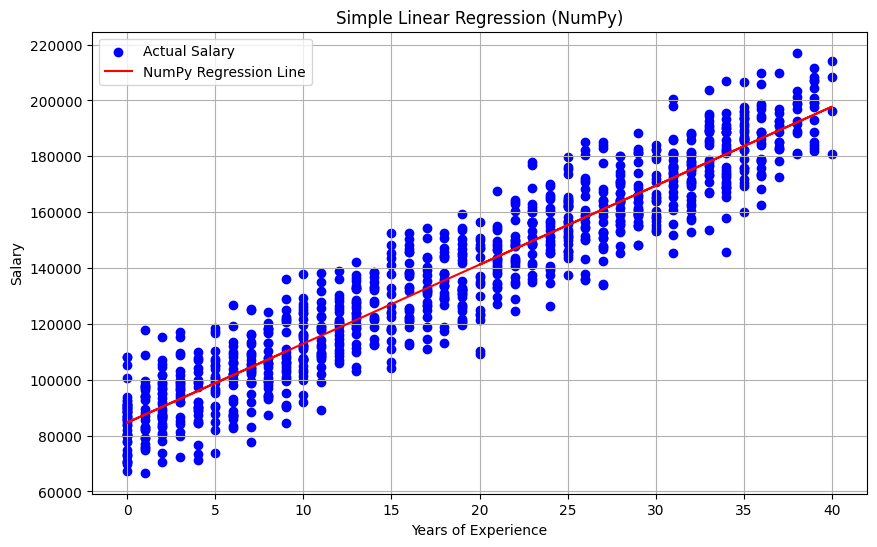

In [7]:
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', label='Actual Salary')
plt.plot(X, y_pred_np, color='red', label='NumPy Regression Line')
plt.title('Simple Linear Regression (NumPy)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

### Residuals Plot (NumPy)

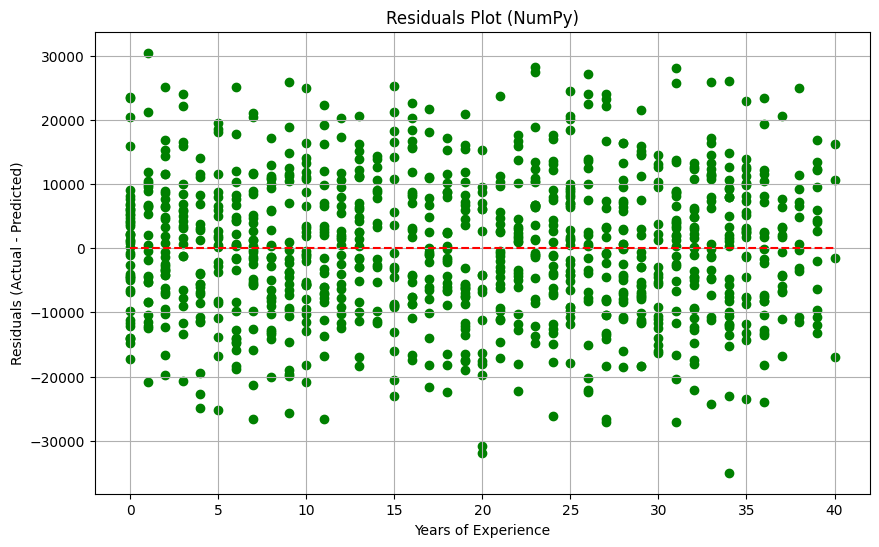

In [8]:
residuals_np = y - y_pred_np

plt.figure(figsize=(10, 6))
plt.scatter(X, residuals_np, color='green')
plt.hlines(y=0, xmin=X.min(), xmax=X.max(), color='red', linestyle='--')
plt.title('Residuals Plot (NumPy)')
plt.xlabel('Years of Experience')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()

### Evaluation Metrics (NumPy)

Calculating Root Mean Squared Error (RMSE) and R-squared (R²) for the NumPy model.

In [9]:
rmse_np = np.sqrt(mean_squared_error(y, y_pred_np))
r2_np = r2_score(y, y_pred_np)

print(f"NumPy RMSE: {rmse_np:.2f}")
print(f"NumPy R-squared: {r2_np:.2f}")

NumPy RMSE: 11058.26
NumPy R-squared: 0.90


## Multiple Linear Regression with NumPy

Now, let's implement multiple linear regression using more features (e.g., 'years_experience', 'age', 'performance_score', 'num_skills') to predict 'annual_salary_usd'.

In [10]:
# Select multiple features for X and the target variable y
X_multi = df[['years_experience', 'age', 'performance_score', 'num_skills']].values
y_multi = df['annual_salary_usd'].values

# Add a bias (intercept) term to X_multi
X_b_multi = np.c_[np.ones(X_multi.shape[0]), X_multi]

# Calculate coefficients using the Normal Equation
theta_best_multi = np.linalg.inv(X_b_multi.T @ X_b_multi) @ X_b_multi.T @ y_multi

print("NumPy Calculated Coefficients (Intercept, Years of Experience, Age, Performance Score, Number of Skills):")
for i, coef in enumerate(theta_best_multi):
    if i == 0:
        print(f"  Intercept: {coef:.2f}")
    else:
        print(f"  Feature {i} Coefficient: {coef:.2f}")

# Make predictions
y_pred_multi_np = X_b_multi @ theta_best_multi

NumPy Calculated Coefficients (Intercept, Years of Experience, Age, Performance Score, Number of Skills):
  Intercept: 56202.76
  Feature 1 Coefficient: 2905.75
  Feature 2 Coefficient: -87.45
  Feature 3 Coefficient: 6104.62
  Feature 4 Coefficient: 1277.53


### Evaluation Metrics (Multiple Linear Regression with NumPy)

Calculating Root Mean Squared Error (RMSE) and R-squared (R²) for the NumPy Multiple Linear Regression model.

In [11]:
rmse_multi_np = np.sqrt(mean_squared_error(y_multi, y_pred_multi_np))
r2_multi_np = r2_score(y_multi, y_pred_multi_np)

print(f"NumPy Multiple Regression RMSE: {rmse_multi_np:.2f}")
print(f"NumPy Multiple Regression R-squared: {r2_multi_np:.2f}")

# Note: Visualizing multiple linear regression directly on a 2D plot is not straightforward.
# We can visualize residuals against predicted values or individual features, but a single regression line plot is not applicable.

NumPy Multiple Regression RMSE: 8878.17
NumPy Multiple Regression R-squared: 0.93


### Residuals Plot (Multiple Linear Regression with NumPy)

We can plot residuals against predicted values or against one of the independent variables.

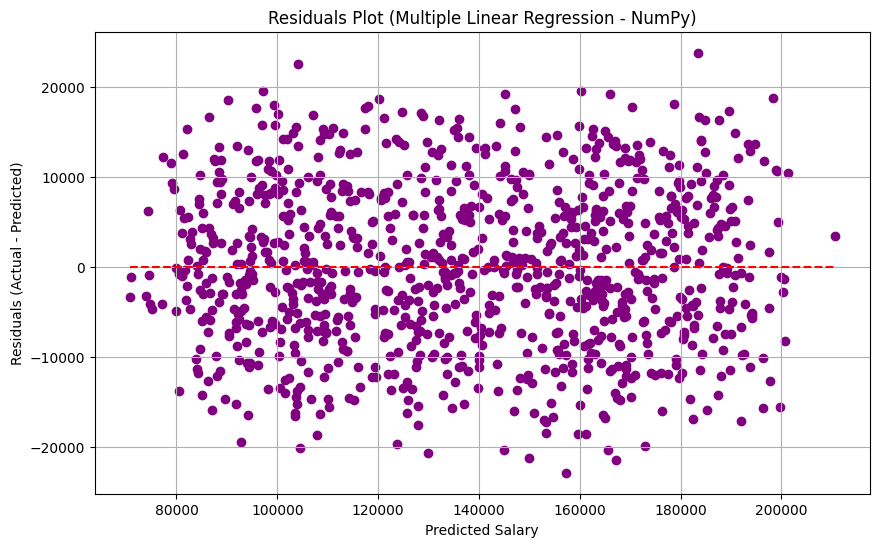

In [12]:
residuals_multi_np = y_multi - y_pred_multi_np

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_multi_np, residuals_multi_np, color='purple')
plt.hlines(y=0, xmin=y_pred_multi_np.min(), xmax=y_pred_multi_np.max(), color='red', linestyle='--')
plt.title('Residuals Plot (Multiple Linear Regression - NumPy)')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()

In [13]:
# Select multiple features for X and the target variable y
X_multi = df[['years_experience', 'age', 'performance_score', 'num_skills']].values
y_multi = df['annual_salary_usd'].values

# Add a bias (intercept) term to X_multi
X_b_multi = np.c_[np.ones(X_multi.shape[0]), X_multi]

# Calculate coefficients using the Normal Equation
theta_best_multi = np.linalg.inv(X_b_multi.T @ X_b_multi) @ X_b_multi.T @ y_multi

print("NumPy Calculated Coefficients (Intercept, Years of Experience, Age, Performance Score, Number of Skills):")
for i, coef in enumerate(theta_best_multi):
    if i == 0:
        print(f"  Intercept: {coef:.2f}")
    else:
        print(f"  Feature {i} Coefficient: {coef:.2f}")

# Make predictions
y_pred_multi_np = X_b_multi @ theta_best_multi

NumPy Calculated Coefficients (Intercept, Years of Experience, Age, Performance Score, Number of Skills):
  Intercept: 56202.76
  Feature 1 Coefficient: 2905.75
  Feature 2 Coefficient: -87.45
  Feature 3 Coefficient: 6104.62
  Feature 4 Coefficient: 1277.53


In [14]:
rmse_multi_np = np.sqrt(mean_squared_error(y_multi, y_pred_multi_np))
r2_multi_np = r2_score(y_multi, y_pred_multi_np)

print(f"NumPy Multiple Regression RMSE: {rmse_multi_np:.2f}")
print(f"NumPy Multiple Regression R-squared: {r2_multi_np:.2f}")

# Note: Visualizing multiple linear regression directly on a 2D plot is not straightforward.
# We can visualize residuals against predicted values or individual features, but a single regression line plot is not applicable.

NumPy Multiple Regression RMSE: 8878.17
NumPy Multiple Regression R-squared: 0.93


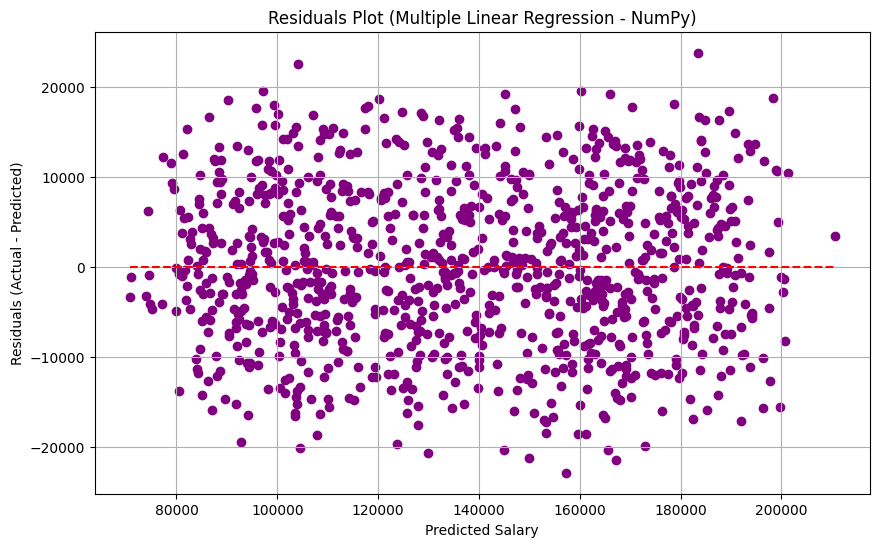

In [15]:
residuals_multi_np = y_multi - y_pred_multi_np

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_multi_np, residuals_multi_np, color='purple')
plt.hlines(y=0, xmin=y_pred_multi_np.min(), xmax=y_pred_multi_np.max(), color='red', linestyle='--')
plt.title('Residuals Plot (Multiple Linear Regression - NumPy)')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()

## Simple Linear Regression with scikit-learn

Now, let's use the `LinearRegression` model from `scikit-learn` to perform simple linear regression for 'years_experience' vs 'annual_salary_usd'.

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Prepare the data for scikit-learn
# X needs to be 2D for scikit-learn models
X_skl_simple = df[['years_experience']]
y_skl_simple = df['annual_salary_usd']

# Split the data into training and testing sets (optional but good practice)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_skl_simple, y_skl_simple, test_size=0.2, random_state=42)

# Create a Linear Regression model object
model_skl_simple = LinearRegression()

# Train the model using the training sets
model_skl_simple.fit(X_train_s, y_train_s)

# Make predictions using the test set
y_pred_skl_simple = model_skl_simple.predict(X_test_s)

# The coefficients
intercept_skl_simple = model_skl_simple.intercept_
slope_skl_simple = model_skl_simple.coef_[0]

print(f"scikit-learn Simple Regression Intercept: {intercept_skl_simple:.2f}")
print(f"scikit-learn Simple Regression Slope: {slope_skl_simple:.2f}")

scikit-learn Simple Regression Intercept: 84831.14
scikit-learn Simple Regression Slope: 2806.47


### Visualization of Simple Linear Regression (scikit-learn)

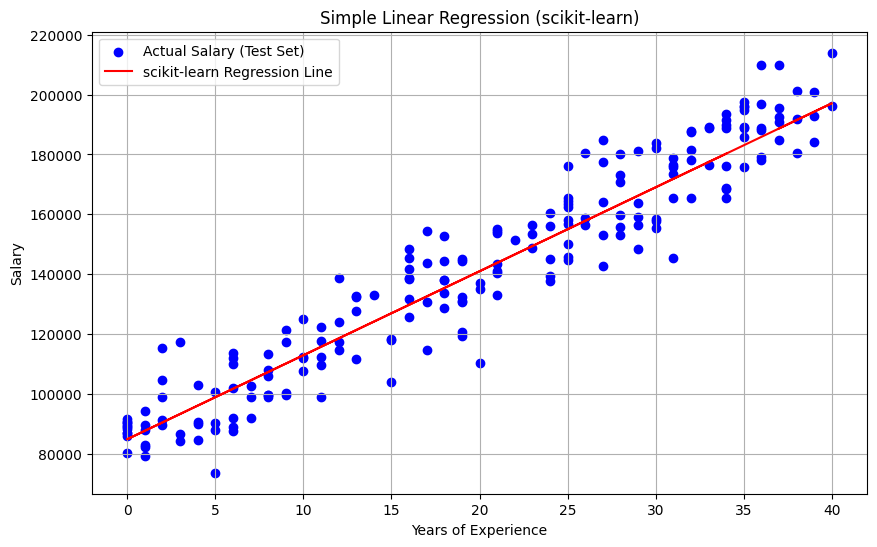

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test_s, y_test_s, color='blue', label='Actual Salary (Test Set)')
plt.plot(X_test_s, y_pred_skl_simple, color='red', label='scikit-learn Regression Line')
plt.title('Simple Linear Regression (scikit-learn)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

### Residuals Plot (Simple Linear Regression with scikit-learn)

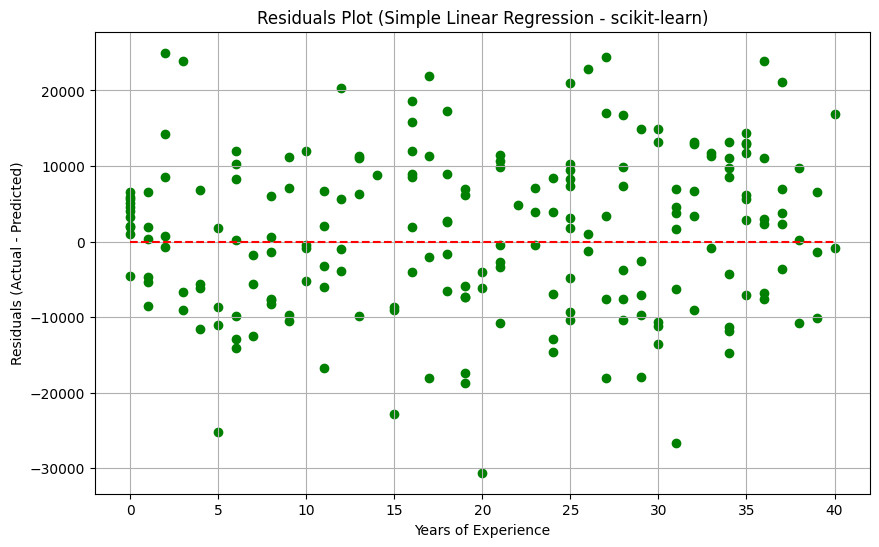

In [18]:
residuals_skl_simple = y_test_s - y_pred_skl_simple

plt.figure(figsize=(10, 6))
plt.scatter(X_test_s, residuals_skl_simple, color='green')
plt.hlines(y=0, xmin=X_test_s.min(), xmax=X_test_s.max(), color='red', linestyle='--')
plt.title('Residuals Plot (Simple Linear Regression - scikit-learn)')
plt.xlabel('Years of Experience')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()

### Evaluation Metrics (Simple Linear Regression with scikit-learn)

Calculating Root Mean Squared Error (RMSE) and R-squared (R²) for the scikit-learn simple linear regression model.

In [19]:
rmse_skl_simple = np.sqrt(mean_squared_error(y_test_s, y_pred_skl_simple))
r2_skl_simple = r2_score(y_test_s, y_pred_skl_simple)

print(f"scikit-learn Simple Regression RMSE: {rmse_skl_simple:.2f}")
print(f"scikit-learn Simple Regression R-squared: {r2_skl_simple:.2f}")

scikit-learn Simple Regression RMSE: 10556.64
scikit-learn Simple Regression R-squared: 0.92


## Multiple Linear Regression with scikit-learn

Now, let's use `scikit-learn`'s `LinearRegression` for multiple linear regression, using the same features as our NumPy multiple regression ('years_experience', 'age', 'performance_score', 'num_skills') to predict 'annual_salary_usd'.

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Prepare the data for scikit-learn multiple regression
# X needs to be 2D for scikit-learn models, and now it will have multiple columns
X_skl_multi = df[['years_experience', 'age', 'performance_score', 'num_skills']]
y_skl_multi = df['annual_salary_usd']

# Split the data into training and testing sets
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_skl_multi, y_skl_multi, test_size=0.2, random_state=42)

# Create a Linear Regression model object
model_skl_multi = LinearRegression()

# Train the model using the training sets
model_skl_multi.fit(X_train_m, y_train_m)

# Make predictions using the test set
y_pred_skl_multi = model_skl_multi.predict(X_test_m)

# The coefficients
intercept_skl_multi = model_skl_multi.intercept_
coefficients_skl_multi = model_skl_multi.coef_

print(f"scikit-learn Multiple Regression Intercept: {intercept_skl_multi:.2f}")
print("scikit-learn Multiple Regression Coefficients (Years of Experience, Age, Performance Score, Number of Skills):")
for i, coef in enumerate(coefficients_skl_multi):
    print(f"  Feature {i+1} Coefficient: {coef:.2f}")

scikit-learn Multiple Regression Intercept: 54392.97
scikit-learn Multiple Regression Coefficients (Years of Experience, Age, Performance Score, Number of Skills):
  Feature 1 Coefficient: 2850.45
  Feature 2 Coefficient: -32.20
  Feature 3 Coefficient: 6136.88
  Feature 4 Coefficient: 1320.83


### Evaluation Metrics (Multiple Linear Regression with scikit-learn)

Calculating Root Mean Squared Error (RMSE) and R-squared (R²) for the scikit-learn multiple linear regression model.

In [27]:
rmse_skl_multi = np.sqrt(mean_squared_error(y_test_m, y_pred_skl_multi))
r2_skl_multi = r2_score(y_test_m, y_pred_skl_multi)

print(f"scikit-learn Multiple Regression RMSE: {rmse_skl_multi:.2f}")
print(f"scikit-learn Multiple Regression R-squared: {r2_skl_multi:.2f}")

scikit-learn Multiple Regression RMSE: 8927.36
scikit-learn Multiple Regression R-squared: 0.94


### Residuals Plot (Multiple Linear Regression with scikit-learn)

Similar to the NumPy multiple regression, we'll plot residuals against predicted values.

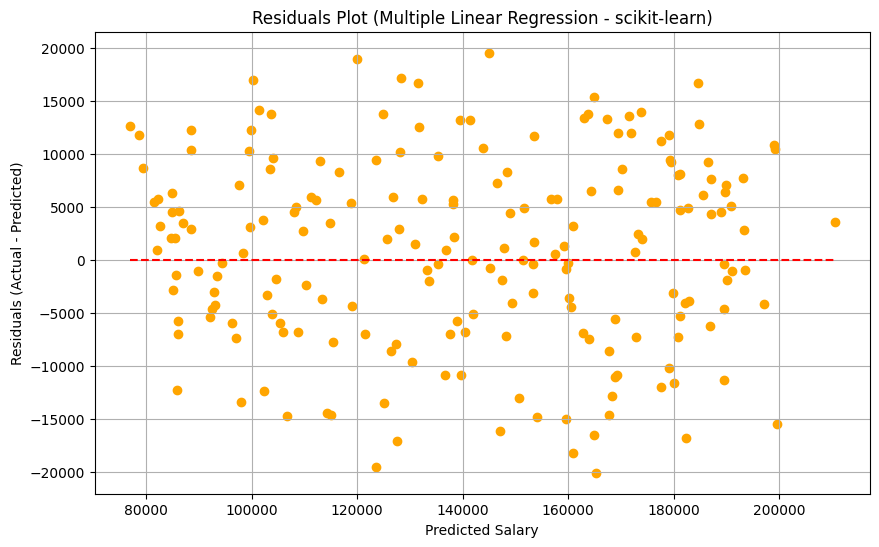

In [28]:
residuals_skl_multi = y_test_m - y_pred_skl_multi

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_skl_multi, residuals_skl_multi, color='orange')
plt.hlines(y=0, xmin=y_pred_skl_multi.min(), xmax=y_pred_skl_multi.max(), color='red', linestyle='--')
plt.title('Residuals Plot (Multiple Linear Regression - scikit-learn)')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()

## Multiple Linear Regression with scikit-learn

Now, let's use `scikit-learn`'s `LinearRegression` for multiple linear regression, using the same features as our NumPy multiple regression ('years_experience', 'age', 'performance_score', 'num_skills') to predict 'annual_salary_usd'.

In [20]:
# Prepare the data for scikit-learn multiple regression
# X needs to be 2D for scikit-learn models, and now it will have multiple columns
X_skl_multi = df[['years_experience', 'age', 'performance_score', 'num_skills']]
y_skl_multi = df['annual_salary_usd']

# Split the data into training and testing sets
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_skl_multi, y_skl_multi, test_size=0.2, random_state=42)

# Create a Linear Regression model object
model_skl_multi = LinearRegression()

# Train the model using the training sets
model_skl_multi.fit(X_train_m, y_train_m)

# Make predictions using the test set
y_pred_skl_multi = model_skl_multi.predict(X_test_m)

# The coefficients
intercept_skl_multi = model_skl_multi.intercept_
coefficients_skl_multi = model_skl_multi.coef_

print(f"scikit-learn Multiple Regression Intercept: {intercept_skl_multi:.2f}")
print("scikit-learn Multiple Regression Coefficients (Years of Experience, Age, Performance Score, Number of Skills):")
for i, coef in enumerate(coefficients_skl_multi):
    print(f"  Feature {i+1} Coefficient: {coef:.2f}")

scikit-learn Multiple Regression Intercept: 54392.97
scikit-learn Multiple Regression Coefficients (Years of Experience, Age, Performance Score, Number of Skills):
  Feature 1 Coefficient: 2850.45
  Feature 2 Coefficient: -32.20
  Feature 3 Coefficient: 6136.88
  Feature 4 Coefficient: 1320.83


### Evaluation Metrics (Multiple Linear Regression with scikit-learn)

Calculating Root Mean Squared Error (RMSE) and R-squared (R²) for the scikit-learn multiple linear regression model.

In [21]:
rmse_skl_multi = np.sqrt(mean_squared_error(y_test_m, y_pred_skl_multi))
r2_skl_multi = r2_score(y_test_m, y_pred_skl_multi)

print(f"scikit-learn Multiple Regression RMSE: {rmse_skl_multi:.2f}")
print(f"scikit-learn Multiple Regression R-squared: {r2_skl_multi:.2f}")

scikit-learn Multiple Regression RMSE: 8927.36
scikit-learn Multiple Regression R-squared: 0.94


### Residuals Plot (Multiple Linear Regression with scikit-learn)

Similar to the NumPy multiple regression, we'll plot residuals against predicted values.

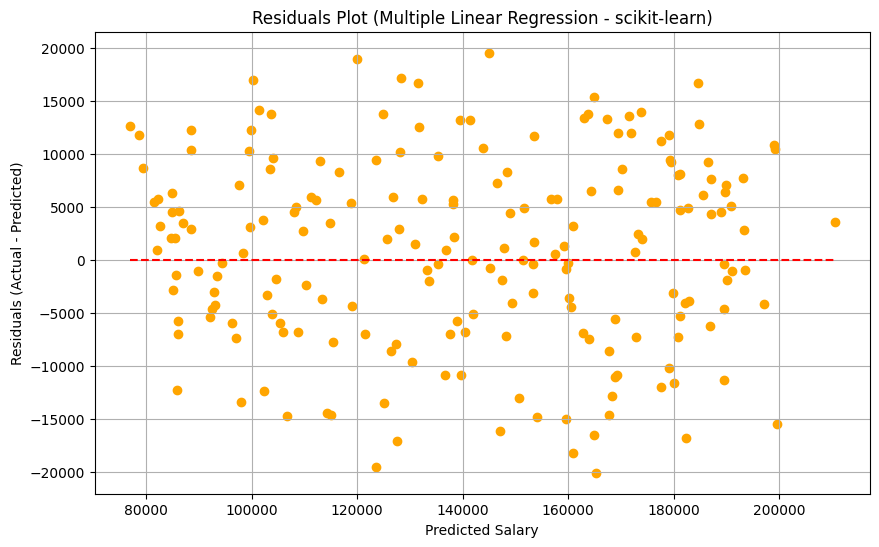

In [22]:
residuals_skl_multi = y_test_m - y_pred_skl_multi

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_skl_multi, residuals_skl_multi, color='orange')
plt.hlines(y=0, xmin=y_pred_skl_multi.min(), xmax=y_pred_skl_multi.max(), color='red', linestyle='--')
plt.title('Residuals Plot (Multiple Linear Regression - scikit-learn)')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Prepare the data for scikit-learn multiple regression
# X needs to be 2D for scikit-learn models, and now it will have multiple columns
X_skl_multi = df[['years_experience', 'age', 'performance_score', 'num_skills']]
y_skl_multi = df['annual_salary_usd']

# Split the data into training and testing sets
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_skl_multi, y_skl_multi, test_size=0.2, random_state=42)

# Create a Linear Regression model object
model_skl_multi = LinearRegression()

# Train the model using the training sets
model_skl_multi.fit(X_train_m, y_train_m)

# Make predictions using the test set
y_pred_skl_multi = model_skl_multi.predict(X_test_m)

# The coefficients
intercept_skl_multi = model_skl_multi.intercept_
coefficients_skl_multi = model_skl_multi.coef_

print(f"scikit-learn Multiple Regression Intercept: {intercept_skl_multi:.2f}")
print("scikit-learn Multiple Regression Coefficients (Years of Experience, Age, Performance Score, Number of Skills):")
for i, coef in enumerate(coefficients_skl_multi):
    print(f"  Feature {i+1} Coefficient: {coef:.2f}")

scikit-learn Multiple Regression Intercept: 54392.97
scikit-learn Multiple Regression Coefficients (Years of Experience, Age, Performance Score, Number of Skills):
  Feature 1 Coefficient: 2850.45
  Feature 2 Coefficient: -32.20
  Feature 3 Coefficient: 6136.88
  Feature 4 Coefficient: 1320.83


In [24]:
rmse_skl_multi = np.sqrt(mean_squared_error(y_test_m, y_pred_skl_multi))
r2_skl_multi = r2_score(y_test_m, y_pred_skl_multi)

print(f"scikit-learn Multiple Regression RMSE: {rmse_skl_multi:.2f}")
print(f"scikit-learn Multiple Regression R-squared: {r2_skl_multi:.2f}")

scikit-learn Multiple Regression RMSE: 8927.36
scikit-learn Multiple Regression R-squared: 0.94


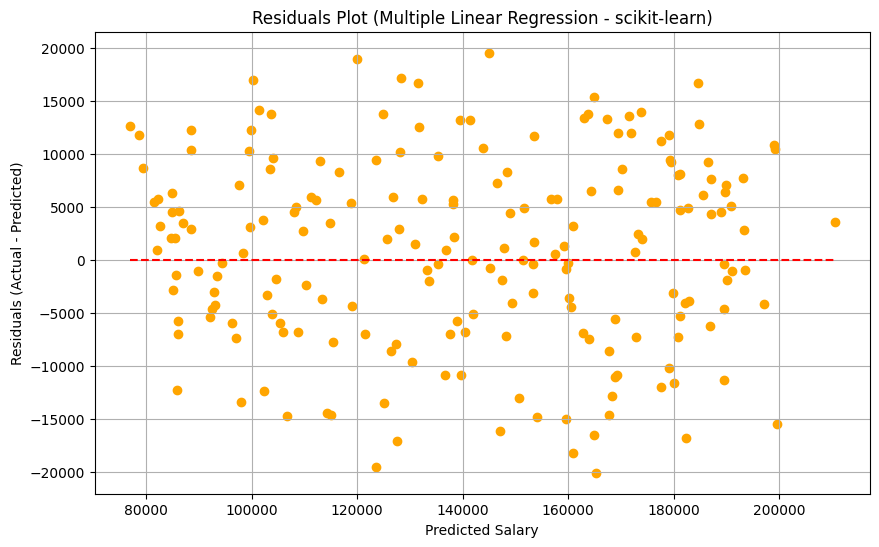

In [25]:
residuals_skl_multi = y_test_m - y_pred_skl_multi

plt.figure(figsize=(10, 6))
plt.scatter(y_pred_skl_multi, residuals_skl_multi, color='orange')
plt.hlines(y=0, xmin=y_pred_skl_multi.min(), xmax=y_pred_skl_multi.max(), color='red', linestyle='--')
plt.title('Residuals Plot (Multiple Linear Regression - scikit-learn)')
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals (Actual - Predicted)')
plt.grid(True)
plt.show()